# 05c · XGBoost

> **Flujo del proyecto** (diagrama del profesor)
> `01 Limpieza` → `02 Exploración` → `03 Creación de variables` → `04 Preparación (split temporal + folds)` →
> `05a Logística` · `05b Random Forest` · `05c XGBoost` · `05d Red neuronal` (cada uno: selección de variables → hiperparámetros) →
> `06 Selección del mejor modelo y prueba final en test`


        Ensamble de árboles con *boosting* (cada árbol corrige los errores del anterior). Maneja faltantes de forma nativa. El desbalance se trata con `scale_pos_weight`, que se busca como hiperparámetro.

        **Pasos (rama del diagrama):** 1) selección de variables con RFECV → 2) búsqueda de hiperparámetros (RandomizedSearchCV)
        → 3) evaluación con el K-Fold temporal (train vs. validación por fold) y umbral → 4) re-entrenamiento con todo el train y guardado.

        Todo usa los **mismos 5 folds temporales con purga** del notebook 04 y la métrica **PR-AUC** (`average_precision`):
        con ~7 % de tardíos, la accuracy no sirve (un modelo que siempre dice "a tiempo" tendría ~93 %).
        **El test no se usa en este notebook.**

In [1]:
import sys, json, time, warnings
from pathlib import Path

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src import config, viz
viz.aplicar_estilo()
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

from src import modelos as M, evaluacion as E

NOMBRE = "XGBoost"
N_ITER = 20
COLOR = viz.COLOR_MODELO[NOMBRE]

In [2]:
X_train = pd.read_parquet(config.DATOS_PROCESSED / "X_train.parquet")
meta_train = pd.read_parquet(config.DATOS_PROCESSED / "meta_train.parquet")
y_train = meta_train["delivery_late"]
folds = [(np.array(f["train"]), np.array(f["val"])) for f in json.loads((config.DATOS_PROCESSED / "folds.json").read_text())]
print(f"Train: {X_train.shape} | {len(folds)} folds temporales | tasa de tardíos {y_train.mean():.2%}")

Train: (68287, 105) | 5 folds temporales | tasa de tardíos 7.59%


## Paso 1 · Selección de variables (RFECV)
RFECV elimina en cada ronda el 10 % de variables menos importantes **para este modelo** y mide el PR-AUC con los 5 folds.
Se queda con el número de variables que maximiza el PR-AUC promedio. Se usa con hiperparámetros base (más rápido).

35 de 105 variables | PR-AUC CV: todas 0.1462 → elegidas 0.1550 | 11 s


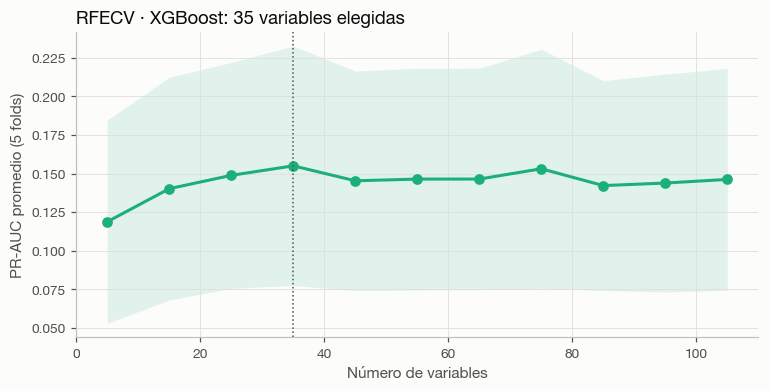

Variables elegidas: ['estimated_delivery_days', 'total_items', 'total_products', 'total_sellers', 'total_freight', 'avg_product_weight', 'avg_product_height', 'avg_dias_limite_envio', 'min_dias_limite_envio', 'avg_distance_km', 'max_distance_km', 'same_state', 'seller_late_rate', 'ruta_late_rate', 'ruta_n_prev', 'global_late_30d', 'global_n_30d', 'estado_late_30d', 'pedidos_ult_7d', 'customer_state_DF', 'customer_state_MG', 'customer_state_PR', 'customer_state_RJ', 'customer_state_SC', 'customer_state_SP', 'customer_state_infrequent_sklearn', 'seller_state_PR', 'seller_state_RJ', 'seller_state_RS', 'seller_state_SP', 'main_payment_type_boleto', 'main_payment_type_credit_card', 'main_category_automotivo', 'main_category_cama_mesa_banho', 'main_category_perfumaria']


In [3]:
t0 = time.time()
variables, curva_rfecv = M.seleccion_rfecv(NOMBRE, X_train, y_train, folds)
t_rfecv = time.time() - t0
pr_todas = float(curva_rfecv.loc[curva_rfecv["n_variables"].idxmax(), "pr_auc_cv"])
pr_rfecv = float(curva_rfecv["pr_auc_cv"].max())
print(f"{len(variables)} de {X_train.shape[1]} variables | PR-AUC CV: todas {pr_todas:.4f} → elegidas {pr_rfecv:.4f} | {t_rfecv:.0f} s")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(curva_rfecv["n_variables"], curva_rfecv["pr_auc_cv"], color=COLOR, marker="o")
ax.fill_between(curva_rfecv["n_variables"], curva_rfecv["pr_auc_cv"] - curva_rfecv["pr_auc_cv_desv"],
                curva_rfecv["pr_auc_cv"] + curva_rfecv["pr_auc_cv_desv"], color=COLOR, alpha=0.12, linewidth=0)
ax.axvline(len(variables), color=viz.TINTA_2, linestyle=":", linewidth=1)
ax.set_xlabel("Número de variables"); ax.set_ylabel("PR-AUC promedio (5 folds)")
ax.set_title(f"RFECV · {NOMBRE}: {len(variables)} variables elegidas")
viz.guardar(fig, f"rfecv_{config.CLAVES_MODELO[NOMBRE]}"); plt.show()
print("Variables elegidas:", variables)

## Paso 2 · Búsqueda de hiperparámetros
`RandomizedSearchCV` sobre las variables elegidas, con los mismos folds. Se reporta también el score en train
para detectar configuraciones sobreajustadas.

In [4]:
t0 = time.time()
mejores_params, busqueda = M.busqueda_hiperparametros(NOMBRE, X_train[variables], y_train, folds, n_iter=N_ITER)
t_busqueda = time.time() - t0
print(f"{N_ITER} configuraciones x {len(folds)} folds en {t_busqueda:.0f} s")
print("Mejores hiperparámetros:", mejores_params)
display(busqueda.head(8).round(4))

20 configuraciones x 5 folds en 31 s
Mejores hiperparámetros: {'modelo__colsample_bytree': 0.5, 'modelo__learning_rate': 0.07722913335507808, 'modelo__max_depth': 3, 'modelo__min_child_weight': 20, 'modelo__n_estimators': 200, 'modelo__reg_lambda': 0.19135880487692303, 'modelo__scale_pos_weight': 6, 'modelo__subsample': 0.6}


,param_modelo__colsample_bytree,param_modelo__learning_rate,param_modelo__max_depth,param_modelo__min_child_weight,param_modelo__n_estimators,param_modelo__reg_lambda,param_modelo__scale_pos_weight,param_modelo__subsample,mean_train_score,mean_test_score,std_test_score,rank_test_score
0,0.5,0.0772,3,20,200,0.1914,6,0.6,0.2536,0.1574,0.0791,1
1,0.5,0.0207,3,20,200,0.2497,12,1.0,0.1903,0.1555,0.0862,2
2,0.7,0.0497,6,5,500,6.9783,12,0.8,0.8351,0.1471,0.0773,3
3,0.5,0.0318,6,10,200,0.4253,12,0.8,0.4761,0.1471,0.0768,4
4,0.5,0.0355,3,10,500,0.2548,1,1.0,0.2655,0.1429,0.0681,5
5,0.9,0.0229,6,1,500,0.1099,3,0.8,0.7654,0.1418,0.0697,6
6,0.5,0.0391,5,10,300,0.1240,12,1.0,0.4728,0.1413,0.0719,7
7,0.7,0.0486,4,1,300,2.3360,6,1.0,0.4032,0.1412,0.0715,8


## Paso 3 · Evaluación con el K-Fold temporal
Con las variables y los hiperparámetros elegidos se entrena en cada fold y se mide **en train y en validación**
(train_avg vs. val_avg del diagrama). El sobreajuste se lee con **ROC-AUC**: el PR-AUC depende de la tasa de tardíos,
que es distinta en el train y en la validación de cada fold, así que no es comparable entre ambos. El umbral de decisión se elige sobre la curva Precision-Recall de todas las
predicciones fuera de fold (el que maximiza el F1 de la clase "tardío"), no con 0.5.

,Fold,PR-AUC train,PR-AUC val,ROC-AUC train,ROC-AUC val,% tardíos train,% tardíos val,Precision val,Recall val,F1 val
0,1,0.2965,0.0387,0.8981,0.5741,3.8359,2.9347,0.0523,0.0479,0.0500
1,2,0.2162,0.0871,0.8489,0.6201,3.2304,5.3159,0.1093,0.0562,0.0742
2,3,0.1991,0.2326,0.8207,0.7219,3.5112,9.9552,0.3246,0.2286,0.2683
3,4,0.2897,0.2066,0.8262,0.6664,5.3299,10.7372,0.2052,0.4051,0.2724
4,5,0.2666,0.2223,0.8132,0.6359,5.3295,12.5648,0.1375,0.8049,0.2349


,PR-AUC train,PR-AUC val,ROC-AUC train,ROC-AUC val,% tardíos train,% tardíos val,Precision val,Recall val,F1 val
promedio,0.2536,0.1574,0.8414,0.6437,4.2474,8.3016,0.1658,0.3085,0.1800
desv,0.0438,0.0885,0.0344,0.0550,1.0110,4.0174,0.1044,0.3137,0.1089


Umbral elegido (F1 máx. fuera de fold): 0.151


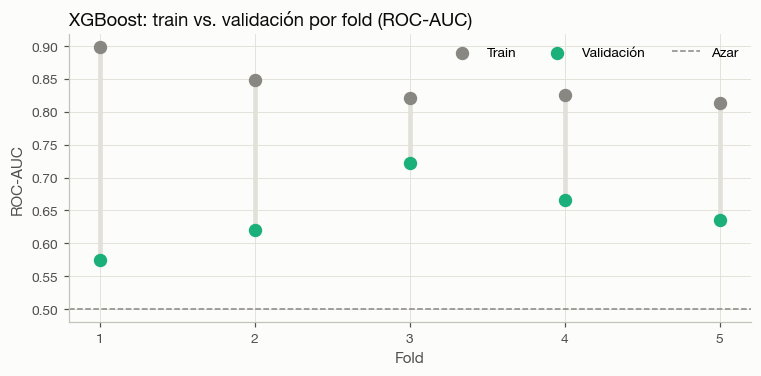

,PR-AUC CV
Todas las variables (params base),0.1462
Variables RFECV (params base),0.1550
Variables RFECV + mejores params (búsqueda),0.1574
Evaluación final (paso 3),0.1574


In [5]:
pipe = M.pipeline_con_parametros(NOMBRE, mejores_params)
tabla_cv, oof, umbral = E.evaluar_cv(E.ajustar_predecir_sklearn(pipe), X_train[variables], y_train, folds)
display(tabla_cv.round(4))
display(E.resumen_cv(tabla_cv).round(4))
print(f"Umbral elegido (F1 máx. fuera de fold): {umbral:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.4))
for _, f in tabla_cv.iterrows():
    ax.plot([f["Fold"]] * 2, [f["ROC-AUC val"], f["ROC-AUC train"]], color=viz.GRID, linewidth=3, zorder=1)
ax.scatter(tabla_cv["Fold"], tabla_cv["ROC-AUC train"], color=viz.NEUTRO, s=60, label="Train", zorder=2)
ax.scatter(tabla_cv["Fold"], tabla_cv["ROC-AUC val"], color=COLOR, s=60, label="Validación", zorder=3)
ax.axhline(0.5, color=viz.NEUTRO, linestyle="--", linewidth=1, label="Azar")
ax.set_xticks(tabla_cv["Fold"]); ax.set_xlabel("Fold"); ax.set_ylabel("ROC-AUC")
ax.set_title(f"{NOMBRE}: train vs. validación por fold (ROC-AUC)"); ax.legend(ncol=3)
viz.guardar(fig, f"cv_{config.CLAVES_MODELO[NOMBRE]}"); plt.show()

evolucion = pd.DataFrame({"PR-AUC CV": [pr_todas, pr_rfecv, float(busqueda.loc[0, "mean_test_score"]), tabla_cv["PR-AUC val"].mean()]},
                         index=["Todas las variables (params base)", "Variables RFECV (params base)",
                                "Variables RFECV + mejores params (búsqueda)", "Evaluación final (paso 3)"])
display(evolucion.round(4))

## Paso 4 · Re-entrenamiento con todo el train y guardado
El modelo final se entrena con todo el train (purgado). Se guardan variables, hiperparámetros, resultados del CV,
predicciones fuera de fold y el modelo en `modelos/`. El notebook 06 compara y abre el test.

In [6]:
modelo_final = M.pipeline_con_parametros(NOMBRE, mejores_params).fit(X_train[variables], y_train)
carpeta = M.guardar_artefactos(NOMBRE, variables, mejores_params, tabla_cv, oof, umbral, modelo_final, extra={
    "pr_auc_todas_vars": pr_todas, "pr_auc_rfecv": pr_rfecv,
    "pr_auc_busqueda": float(busqueda.loc[0, "mean_test_score"]),
    "n_variables_total": X_train.shape[1], "segundos_rfecv": t_rfecv, "segundos_busqueda": t_busqueda,
})
curva_rfecv.to_csv(carpeta / "rfecv_curva.csv", index=False)
busqueda.to_csv(carpeta / "busqueda.csv", index=False)
print("Artefactos guardados en", carpeta)

Artefactos guardados en /Users/fabiolajrz/Documents/proyecto_final_equipo_3/modelos/xgboost


## Interpretación

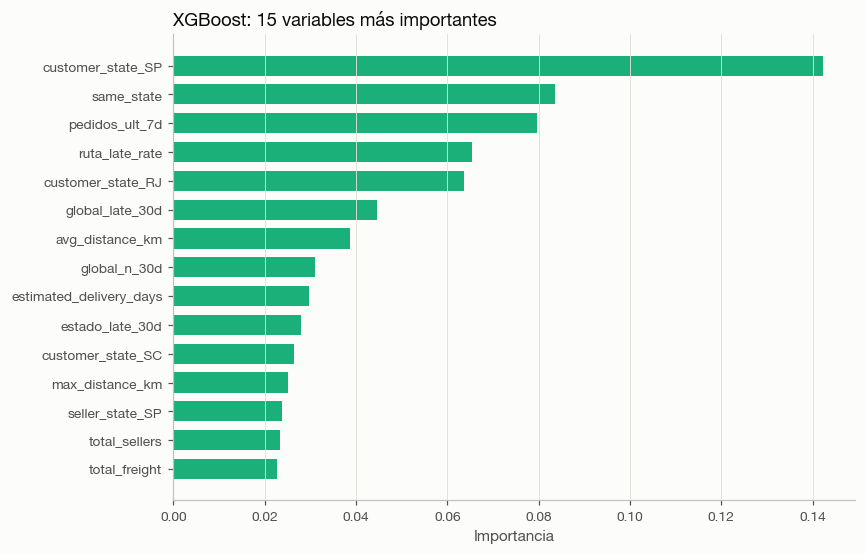

In [7]:
imp = pd.Series(modelo_final.named_steps["modelo"].feature_importances_, index=variables).sort_values(ascending=False)
top = imp.head(15).sort_values()
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top.values, color=COLOR, height=0.7); ax.grid(axis="y", visible=False)
ax.set_xlabel("Importancia"); ax.set_title(f"{NOMBRE}: 15 variables más importantes")
viz.guardar(fig, f"importancia_{config.CLAVES_MODELO[NOMBRE]}"); plt.show()
imp.to_csv(carpeta / "importancias.csv")